# Evaluación Formativa 2 — Modelamiento predictivo

**Curso:** MCDI501 — Estadística Computacional para la Toma de Decisiones  
**Proyecto:** *Online Shoppers Purchasing Intention*  
**Integrantes:** Verónica Durán Cisterna · Raúl Moya Arriagada · Daniela Rojas Vilches · Manuel Sánchez Cárcamo  
**Docente:** Dr. Jean Paul Maidana González  

## Objetivo

Ensayar el flujo completo de modelamiento predictivo mediante **regresión logística**, integrando explícitamente los resultados obtenidos en las Evaluaciones Sumativas 1 y 2. Se prepara el conjunto de datos, se seleccionan predictores sustentados en evidencia previa, se ajusta e interpreta el modelo y se evalúa su desempeño sobre un conjunto de prueba.

La pregunta que guía el proyecto se mantiene en términos asociativos:

> **¿Qué características del comportamiento de navegación de los usuarios se relacionan con la probabilidad de que una sesión de comercio electrónico termine en una compra?**

El análisis no pretende establecer relaciones causales.

## 1. Librerías y reproducibilidad

Se fija `RANDOM_STATE = 42` para hacer reproducible la partición entrenamiento/prueba. Se utilizan `pandas` y `numpy` para manipulación, `statsmodels` para inferencia y VIF, y `scikit-learn` para preprocesamiento y evaluación predictiva.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, roc_curve, roc_auc_score
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Entorno preparado. Semilla:", RANDOM_STATE)

Entorno preparado. Semilla: 42


## 2. Carga y verificación del dataset

El notebook busca el archivo mediante rutas relativas habituales del repositorio, de modo que pueda ejecutarse desde la raíz o desde una subcarpeta como `F2/`.

La unidad de análisis es una **sesión de navegación** y la variable objetivo es `Revenue` (`True` = la sesión termina en compra).

In [2]:
candidatos = [
    Path("data/raw/online_shoppers_intention.csv"),
    Path("../data/raw/online_shoppers_intention.csv"),
    Path("online_shoppers_intention.csv"),
]

ruta = next((p for p in candidatos if p.exists()), None)

if ruta is None:
    raise FileNotFoundError(
        "No se encontró online_shoppers_intention.csv. "
        "Ejecute el notebook desde la raíz del repositorio o desde F2/."
    )

df = pd.read_csv(ruta)

print("Archivo:", ruta.resolve())
print("Dimensiones:", df.shape)
display(df.head())

Archivo: C:\Users\eliza\Desktop\ESTUDIOS\MAGÍSTER\2 ESTADÍSITICAS COMPUTACIONAL\Proyecto Estadística\Online-Shoppers-Purchasing-Intention\data\raw\online_shoppers_intention.csv
Dimensiones: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
print("Tipos de datos:")
display(df.dtypes.to_frame("dtype"))

print("\nValores faltantes totales:", int(df.isna().sum().sum()))
print("Filas con atributos exactamente coincidentes:", int(df.duplicated().sum()))

print("\nDistribución de Revenue:")
display(
    df["Revenue"]
    .value_counts(dropna=False)
    .rename("n")
    .to_frame()
    .assign(proporcion=lambda x: x["n"] / len(df))
)

Tipos de datos:


,dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64



Valores faltantes totales: 0
Filas con atributos exactamente coincidentes: 125

Distribución de Revenue:


,n,proporcion
Revenue,,
False,10422,0.845255
True,1908,0.154745


## 3. Integración explícita de resultados de S1 y S2

### 3.1 Hallazgos relevantes de S1

S1 mostró:

- **12.330 sesiones y 18 variables**, sin valores faltantes.
- `Revenue` presenta desbalance: aproximadamente **15,47 %** de las sesiones terminan en compra.
- Las variables numéricas presentan asimetría positiva y valores extremos; por ello, las medias se interpretaron junto con mediana e IQR.
- `PageValues` mostró una asociación muy marcada con `Revenue`. La prueba U de Mann–Whitney rechazó igualdad de distribuciones y presentó un efecto grande (`r_rb ≈ 0,727`).
- `VisitorType` se asoció con `Revenue` mediante χ², aunque el tamaño del efecto fue pequeño (`V de Cramér ≈ 0,105`).
- Se identificaron correlaciones elevadas entre `BounceRates`–`ExitRates` (`r ≈ 0,913`) y `ProductRelated`–`ProductRelated_Duration` (`r ≈ 0,861`).

### 3.2 Hallazgos relevantes de S2

S2 validó mediante remuestreo que:

- Los IC bootstrap/BCa de `ProductRelated_Duration`, `PageValues` y `ExitRates` son próximos a los intervalos clásicos.
- La asociación de `PageValues` con `Revenue` se mantuvo en una prueba de permutación (`p ≈ 0,0001`).
- La asociación `VisitorType`–`Revenue` también se mantuvo al permutar el estadístico χ² (`p ≈ 0,0001`).
- Los IC bootstrap de las correlaciones `BounceRates`–`ExitRates` y `ProductRelated`–`ProductRelated_Duration` no incluyen cero y confirman relaciones altas y estables.
- El análisis robusto mostró sensibilidad de las medias a las colas, especialmente en `PageValues`; sin embargo, el jackknife indicó que ninguna observación individual domina por sí sola las estimaciones.

### Implicancia para esta Formativa

Los valores extremos **no se eliminarán automáticamente**, porque S2 mostró que forman parte importante de la estructura distributiva y no se demostró que sean errores. La multicolinealidad se reduce evitando incluir simultáneamente predictores altamente redundantes.

## 4. Preparación de datos para modelamiento

### 4.1 Valores faltantes

La pauta solicita aplicar una estrategia básica de tratamiento. Primero se verifica la existencia real de faltantes. Si no existen —como se documentó en S1— **no corresponde inventar imputaciones ni eliminar observaciones**. Si aparecieran faltantes por una versión distinta del archivo, se aplicará una estrategia simple y reproducible: mediana para numéricas y moda para categóricas.

In [4]:
faltantes = df.isna().sum()
display(faltantes[faltantes > 0].to_frame("n_faltantes"))

if faltantes.sum() == 0:
    print("No existen valores faltantes: no se requiere imputación ni eliminación de filas.")
else:
    print("Se detectaron faltantes. Se aplicará imputación simple antes del modelamiento.")

,n_faltantes


No existen valores faltantes: no se requiere imputación ni eliminación de filas.


### 4.2 Selección de predictores

Se seleccionan cinco variables:

1. **`PageValues`**: evidencia fuerte en S1 y validación por permutación en S2. Se mantiene para esta práctica, pero se documenta el riesgo de *target leakage* por su proximidad conceptual a la transacción.
2. **`ExitRates`**: representa abandono y mostró asociación negativa con compra. Se prefiere sobre `BounceRates` para no introducir simultáneamente el par altamente correlacionado.
3. **`ProductRelated_Duration`**: representa intensidad temporal de navegación en páginas de producto. Se prefiere sobre `ProductRelated`, evitando el par redundante validado en S2.
4. **`VisitorType`**: asociación con `Revenue` confirmada en S1 y por permutación en S2, aunque de magnitud pequeña.
5. **`Weekend`**: aporta información temporal no redundante; en S1 la conversión fue descriptivamente mayor en fin de semana.

Esta selección combina evidencia estadística previa, interpretabilidad y control básico de redundancia.

In [5]:
predictores = [
    "PageValues",
    "ExitRates",
    "ProductRelated_Duration",
    "VisitorType",
    "Weekend",
]
target = "Revenue"

modelo_df = df[predictores + [target]].copy()

# Revenue a 0/1
modelo_df[target] = modelo_df[target].astype(int)

print("Variables seleccionadas:", predictores)
display(modelo_df.head())

Variables seleccionadas: ['PageValues', 'ExitRates', 'ProductRelated_Duration', 'VisitorType', 'Weekend']


,PageValues,ExitRates,ProductRelated_Duration,VisitorType,Weekend,Revenue
0,0.0,0.20,0.000000,Returning_Visitor,False,0
1,0.0,0.10,64.000000,Returning_Visitor,False,0
2,0.0,0.20,0.000000,Returning_Visitor,False,0
3,0.0,0.14,2.666667,Returning_Visitor,False,0
4,0.0,0.05,627.500000,Returning_Visitor,True,0


### 4.3 Partición entrenamiento/prueba 70/30

La partición se realiza **antes de estimar parámetros de preprocesamiento**, con `random_state=42` y `stratify=y`. La estratificación es importante debido al desbalance de `Revenue`, ya que mantiene aproximadamente la misma proporción de compra en entrenamiento y prueba.

In [6]:
X = modelo_df[predictores].copy()
y = modelo_df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Compra train: {y_train.mean():.4%}")
print(f"Compra test : {y_test.mean():.4%}")

Train: (8631, 5) | Test: (3699, 5)
Compra train: 15.4791%
Compra test : 15.4636%


### 4.4 Codificación y estandarización

Las variables numéricas se estandarizan usando parámetros aprendidos **solo en entrenamiento**. `VisitorType` se codifica mediante *one-hot encoding*, usando una categoría de referencia. `Weekend` se transforma a 0/1.

La estandarización no es obligatoria matemáticamente para la regresión logística, pero facilita la optimización y permite interpretar los coeficientes de variables numéricas por incremento de una desviación estándar.

In [7]:
numeric_features = ["PageValues", "ExitRates", "ProductRelated_Duration"]
categorical_features = ["VisitorType"]

# Conversión explícita de Weekend a entero
X_train = X_train.copy()
X_test = X_test.copy()
X_train["Weekend"] = X_train["Weekend"].astype(int)
X_test["Weekend"] = X_test["Weekend"].astype(int)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_model = pd.DataFrame(X_train_proc, columns=feature_names, index=X_train.index)
X_test_model = pd.DataFrame(X_test_proc, columns=feature_names, index=X_test.index)

display(X_train_model.head())
print("Variables finales del modelo:", list(X_train_model.columns))

,PageValues,ExitRates,ProductRelated_Duration,VisitorType_Other,VisitorType_Returning_Visitor,Weekend
7460,-0.320111,-0.668651,-0.440323,0.0,0.0,0.0
4687,-0.320111,-0.668651,-0.354857,0.0,1.0,0.0
790,-0.320111,-0.252391,-0.490119,0.0,1.0,0.0
9057,-0.320111,-0.545198,-0.041507,0.0,1.0,0.0
225,-0.320111,1.171218,-0.608351,0.0,1.0,1.0


Variables finales del modelo: ['PageValues', 'ExitRates', 'ProductRelated_Duration', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'Weekend']


## 5. Modelo de regresión logística

Para cumplir el componente inferencial se ajusta primero una regresión logística con `statsmodels`. Esto permite obtener coeficientes, errores estándar, pruebas de significancia e intervalos de confianza. Posteriormente se interpretan los **odds ratios** (`exp(β)`).

Para las variables numéricas estandarizadas, el OR representa el cambio multiplicativo en los *odds* de compra asociado a un aumento de **1 desviación estándar**, manteniendo constantes los demás predictores.

In [8]:
X_sm = sm.add_constant(X_train_model, has_constant="add")

logit_sm = sm.Logit(y_train, X_sm)
resultado_sm = logit_sm.fit(disp=False, maxiter=1000)

print(resultado_sm.summary())

                           Logit Regression Results                           
Dep. Variable:                Revenue   No. Observations:                 8631
Model:                          Logit   Df Residuals:                     8624
Method:                           MLE   Df Model:                            6
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.3114
Time:                        19:37:33   Log-Likelihood:                -2561.2
converged:                       True   LL-Null:                       -3719.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                            -2.0374      0.109    -18.726      0.000      -2.251      -1.824
PageValues                        1.5070      0.052     28.948      0.000 

In [9]:
coef = resultado_sm.params
conf = resultado_sm.conf_int()

tabla_coef = pd.DataFrame({
    "Coeficiente": coef,
    "Odds_ratio": np.exp(coef),
    "p_valor": resultado_sm.pvalues,
    "OR_IC95_inf": np.exp(conf[0]),
    "OR_IC95_sup": np.exp(conf[1]),
})

tabla_coef["Significativo_5%"] = np.where(
    tabla_coef["p_valor"] < 0.05, "Sí", "No"
)

display(tabla_coef.round(4))

,Coeficiente,Odds_ratio,p_valor,OR_IC95_inf,OR_IC95_sup,Significativo_5%
const,-2.0374,0.1304,0.0000,0.1053,0.1613,Sí
PageValues,1.5070,4.5133,0.0000,4.0755,4.9981,Sí
ExitRates,-0.9527,0.3857,0.0000,0.3180,0.4679,Sí
ProductRelated_Duration,0.2629,1.3007,0.0000,1.2211,1.3856,Sí
VisitorType_Other,-0.6839,0.5046,0.2708,0.1494,1.7044,No
VisitorType_Returning_Visitor,-0.2605,0.7707,0.0106,0.6310,0.9412,Sí
Weekend,0.1683,1.1833,0.0453,1.0035,1.3953,Sí


### 5.1 Interpretación automática de coeficientes y odds ratios

La tabla siguiente genera una lectura consistente de cada predictor. La interpretación final debe considerar simultáneamente signo, OR, intervalo de confianza, p-valor y contexto.

In [10]:
for variable in tabla_coef.index:
    if variable == "const":
        continue

    beta = tabla_coef.loc[variable, "Coeficiente"]
    or_ = tabla_coef.loc[variable, "Odds_ratio"]
    p = tabla_coef.loc[variable, "p_valor"]
    sentido = "aumentan" if beta > 0 else "disminuyen"
    sig = "estadísticamente significativo" if p < 0.05 else "no estadísticamente significativo"

    print(
        f"{variable}: β={beta:.4f}, OR={or_:.4f}, p={p:.4g}. "
        f"Manteniendo constantes los demás predictores, los odds de compra {sentido}; "
        f"el predictor es {sig} al 5%."
    )

PageValues: β=1.5070, OR=4.5133, p=2.955e-184. Manteniendo constantes los demás predictores, los odds de compra aumentan; el predictor es estadísticamente significativo al 5%.
ExitRates: β=-0.9527, OR=0.3857, p=4.208e-22. Manteniendo constantes los demás predictores, los odds de compra disminuyen; el predictor es estadísticamente significativo al 5%.
ProductRelated_Duration: β=0.2629, OR=1.3007, p=3.578e-16. Manteniendo constantes los demás predictores, los odds de compra aumentan; el predictor es estadísticamente significativo al 5%.
VisitorType_Other: β=-0.6839, OR=0.5046, p=0.2708. Manteniendo constantes los demás predictores, los odds de compra disminuyen; el predictor es no estadísticamente significativo al 5%.
VisitorType_Returning_Visitor: β=-0.2605, OR=0.7707, p=0.01065. Manteniendo constantes los demás predictores, los odds de compra disminuyen; el predictor es estadísticamente significativo al 5%.
Weekend: β=0.1683, OR=1.1833, p=0.04533. Manteniendo constantes los demás predi

### 5.2 Diagnóstico de multicolinealidad mediante VIF

El VIF se calcula sobre las variables predictoras ya codificadas. Como referencia práctica:

- VIF cercano a 1: baja colinealidad.
- VIF > 5: requiere atención.
- VIF > 10: problema severo.

La selección previa ya evita incluir simultáneamente los dos pares de correlaciones altas validadas en S2.

In [11]:
X_vif = X_train_model.astype(float).copy()

tabla_vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
}).sort_values("VIF", ascending=False)

display(tabla_vif.round(3))

if tabla_vif["VIF"].max() > 5:
    print("Atención: al menos un predictor presenta VIF > 5.")
else:
    print("No se observan problemas relevantes de multicolinealidad según el umbral VIF > 5.")

,Variable,VIF
1,ExitRates,1.151
4,VisitorType_Returning_Visitor,1.127
2,ProductRelated_Duration,1.101
3,VisitorType_Other,1.057
0,PageValues,1.043
5,Weekend,1.006


No se observan problemas relevantes de multicolinealidad según el umbral VIF > 5.


## 6. Evaluación de desempeño predictivo

Para evaluar generalización, el desempeño se calcula **exclusivamente sobre el conjunto de prueba**. Se utiliza el umbral convencional de 0,50 para la clasificación principal.

Debido al desbalance de `Revenue`, **accuracy no debe interpretarse aisladamente**. Son especialmente relevantes:

- **Precision**: de las sesiones predichas como compra, qué proporción realmente compra.
- **Recall (sensibilidad)**: de las sesiones que realmente compran, qué proporción identifica el modelo.
- **F1-score**: equilibrio entre precision y recall.
- **ROC-AUC**: capacidad de discriminación a través de todos los umbrales.

In [12]:
# Las probabilidades provienen del modelo inferencial ajustado con statsmodels
X_test_sm = sm.add_constant(X_test_model, has_constant="add")
prob_test = resultado_sm.predict(X_test_sm)
pred_test = (prob_test >= 0.50).astype(int)

metricas = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Valor": [
        accuracy_score(y_test, pred_test),
        precision_score(y_test, pred_test, zero_division=0),
        recall_score(y_test, pred_test, zero_division=0),
        f1_score(y_test, pred_test, zero_division=0),
        roc_auc_score(y_test, prob_test),
    ]
})

display(metricas.round(4))

print("\nReporte de clasificación:")
print(classification_report(y_test, pred_test, target_names=["No compra", "Compra"], digits=4))

,Métrica,Valor
0,Accuracy,0.8824
1,Precision,0.7546
2,Recall,0.3549
3,F1-score,0.4828
4,ROC-AUC,0.8666



Reporte de clasificación:
              precision    recall  f1-score   support

   No compra     0.8924    0.9789    0.9337      3127
      Compra     0.7546    0.3549    0.4828       572

    accuracy                         0.8824      3699
   macro avg     0.8235    0.6669    0.7082      3699
weighted avg     0.8711    0.8824    0.8639      3699



### 6.1 Matriz de confusión

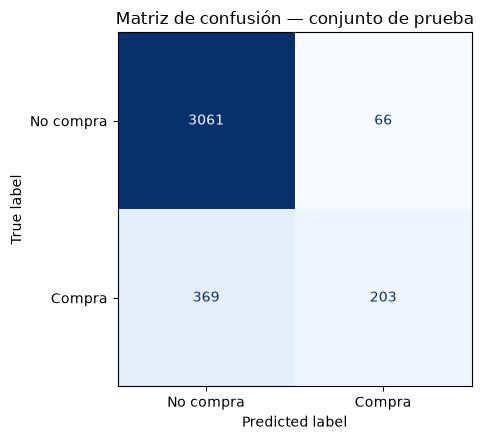

TN=3061, FP=66, FN=369, TP=203


In [13]:
cm = confusion_matrix(y_test, pred_test)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No compra", "Compra"]
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Matriz de confusión — conjunto de prueba")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

**Interpretación contextual:** en este problema los **falsos negativos (FN)** representan sesiones que sí terminaron en compra pero que el modelo clasificó como “no compra”. Por ello, un recall bajo de la clase positiva indicaría que el modelo pierde una fracción importante de compradores reales, aunque su accuracy global pudiera parecer elevada.

### 6.2 Curva ROC y AUC

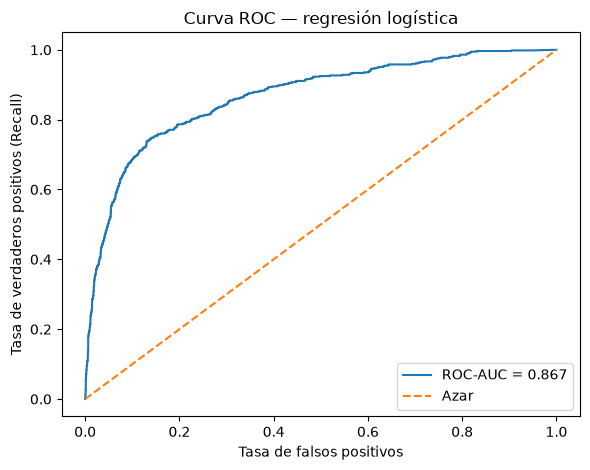

AUC = 0.8666: buena capacidad discriminativa.


In [14]:
fpr, tpr, thresholds = roc_curve(y_test, prob_test)
auc = roc_auc_score(y_test, prob_test)

fig, ax = plt.subplots(figsize=(6, 4.8))
ax.plot(fpr, tpr, label=f"ROC-AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", label="Azar")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.set_title("Curva ROC — regresión logística")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

if auc < 0.60:
    lectura_auc = "capacidad discriminativa baja"
elif auc < 0.70:
    lectura_auc = "capacidad discriminativa limitada"
elif auc < 0.80:
    lectura_auc = "capacidad discriminativa aceptable"
elif auc < 0.90:
    lectura_auc = "buena capacidad discriminativa"
else:
    lectura_auc = "capacidad discriminativa muy alta"

print(f"AUC = {auc:.4f}: {lectura_auc}.")

### 6.3 Comparación con una referencia simple

Dado el desbalance de clases, se calcula el accuracy que obtendría una regla ingenua que predijera siempre la clase mayoritaria (“no compra”). Esta comparación evita atribuir mérito predictivo a un accuracy alto que pueda explicarse solo por la distribución de clases.

In [15]:
accuracy_baseline = max(y_test.mean(), 1 - y_test.mean())
accuracy_modelo = accuracy_score(y_test, pred_test)

print(f"Accuracy baseline clase mayoritaria: {accuracy_baseline:.4f}")
print(f"Accuracy modelo logístico          : {accuracy_modelo:.4f}")
print(f"Mejora absoluta                    : {accuracy_modelo - accuracy_baseline:.4f}")

Accuracy baseline clase mayoritaria: 0.8454
Accuracy modelo logístico          : 0.8824
Mejora absoluta                    : 0.0370


## 7. Análisis crítico del modelo

La evaluación debe considerar dos dimensiones distintas:

1. **Inferencial:** los coeficientes, odds ratios, p-valores y VIF permiten estudiar la relación de los predictores con los odds de compra y diagnosticar multicolinealidad.
2. **Predictiva:** la matriz de confusión, precision, recall, F1 y ROC-AUC permiten evaluar cuánto generaliza el modelo a sesiones no utilizadas durante el ajuste.

Un predictor puede ser estadísticamente significativo sin que el modelo completo tenga desempeño suficiente para una aplicación práctica. Del mismo modo, un accuracy alto no garantiza una buena identificación de la clase minoritaria.

### Precaución especial: `PageValues`

`PageValues` se incluye porque S1 y S2 entregaron evidencia consistente de una asociación fuerte con `Revenue`. Sin embargo, es una variable conceptualmente próxima a la transacción. Para S3 será recomendable comparar explícitamente un modelo **con** y **sin `PageValues`**. Si el desempeño cae de forma marcada al retirarla, deberá discutirse cuánto del poder predictivo depende de información que podría no estar disponible en el momento real en que se quisiera anticipar la compra.

## 8. Síntesis y reflexión final

Los resultados obtenidos en S1 y S2 se integraron directamente en la construcción del modelo de regresión logística. S1 permitió identificar el desbalance de `Revenue`, la fuerte asociación de `PageValues` con la compra, la relación de `VisitorType` con la variable objetivo y pares de variables altamente correlacionadas. S2 confirmó mediante remuestreo la estabilidad de varios de estos resultados. En particular, las correlaciones elevadas y estables entre `BounceRates`–`ExitRates` y `ProductRelated`–`ProductRelated_Duration` justificaron no incorporar simultáneamente ambos miembros de cada par. Esta decisión resultó consistente con el diagnóstico posterior de multicolinealidad, ya que todos los predictores del modelo presentaron VIF inferiores a 1,2.

El modelo incorporó `PageValues`, `ExitRates`, `ProductRelated_Duration`, `VisitorType` y `Weekend`. `PageValues` presentó el efecto de mayor magnitud: su odds ratio fue aproximadamente 4,51, indicando que un aumento de una desviación estándar se asocia con una multiplicación de los odds de compra por aproximadamente 4,5, manteniendo constantes los demás predictores. `ExitRates` presentó una relación negativa (OR ≈ 0,39), mientras que `ProductRelated_Duration` mostró una asociación positiva (OR ≈ 1,30). La categoría `Returning_Visitor` y `Weekend` también resultaron estadísticamente significativas al 5 %, mientras que `VisitorType_Other` no presentó evidencia suficiente de asociación una vez controlados los demás predictores.

En el conjunto de prueba, el modelo alcanzó un accuracy de 88,24 %, precision de 75,46 %, recall de 35,49 %, F1-score de 48,28 % y ROC-AUC de 0,8666. El AUC indica una buena capacidad global de discriminación; sin embargo, el desempeño no debe evaluarse únicamente mediante accuracy debido al desbalance de la variable objetivo. La matriz de confusión mostró 3.061 verdaderos negativos, 66 falsos positivos, 369 falsos negativos y 203 verdaderos positivos. Por lo tanto, con el umbral convencional de 0,50 el modelo identifica correctamente solo el 35,49 % de las sesiones que realmente terminan en compra. Además, el accuracy de una clasificación ingenua basada exclusivamente en la clase mayoritaria sería aproximadamente 84,54 %, por lo que la mejora del modelo en esta métrica es de alrededor de 3,70 puntos porcentuales.

Los valores extremos no fueron eliminados automáticamente. Esta decisión es coherente con S2, donde las distribuciones mostraron sensibilidad a las colas, especialmente `PageValues`, pero el análisis jackknife no evidenció que una única observación dominara las estimaciones. Tampoco se realizó imputación, ya que el conjunto de datos no presenta valores faltantes. La partición 70/30 se realizó de forma estratificada y la estandarización se estimó únicamente con los datos de entrenamiento para evitar fuga de información desde el conjunto de prueba.

De cara a la Sumativa 3, el principal desafío será mejorar la detección de la clase compra sin deteriorar excesivamente la precision. Se propone evaluar distintos umbrales de clasificación, utilizar validación cruzada y estudiar estrategias para el desbalance de clases. Asimismo, será especialmente importante comparar modelos con y sin `PageValues`, dado que su fuerte capacidad predictiva y su proximidad conceptual a la transacción podrían constituir una fuente de *target leakage*. Estas mejoras permitirán determinar si el desempeño observado se mantiene bajo especificaciones alternativas y seleccionar un modelo final considerando no solo su capacidad discriminativa, sino también su utilidad para identificar correctamente sesiones con intención de compra.

## 9. Checklist de la rúbrica

| Criterio | Evidencia en el notebook |
|---|---|
| Preparación de datos (21 pts) | S1/S2 explícitos, faltantes, outliers, selección, train/test 70/30 estratificado y estandarización |
| Regresión logística (30 pts) | 5 predictores justificados, resumen, coeficientes, OR, significancia y VIF |
| Desempeño predictivo (30 pts) | Matriz de confusión, accuracy, precision, recall, F1, ROC y AUC con interpretación |
| Síntesis y reflexión (15 pts) | Integración S1/S2, evaluación crítica y mejoras concretas para S3 |

**Total de criterios cubiertos por diseño: 96 puntos posibles.** La calificación final depende de la ejecución correcta del notebook, los resultados obtenidos y la evaluación docente.